<a href="https://colab.research.google.com/github/nuralfiyanti/PCVK_Ganjil2026/blob/main/Week07_17(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama  : Nur Alfiyanti

NIM   : 244107020055

Kelas : TI-3E

Modul 7 Segmentasi Citra dengan Thresholding

## **D. Praktikum**

**1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab
terhubung dengan Github Anda, lanjutkan dengan memilih repository yang telah
digunakan pada praktikum minggu lalu, rename file menjadi “Week7.ipynb”.
Kemudian import folder yang ada di Drive Anda dengan cara sebagai berikut**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2. Import beberapa library berikut yang akan digunakan selama uji coba praktikum
minggu ke-7 berikut.**

In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

**3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV), dengan
threshold= 200, secara manual sehingga menghasilkan tampilan seperti berikut:**

In [6]:
filename = '/content/drive/MyDrive/PCVK/gradient.png'
gradient = cv.imread(filename)

if gradient is None:
    print("Citra gradient tidak ditemukan!")
else:
    print("Citra gradient berhasil dibaca")
    print("Ukuran citra :", gradient.shape)

Citra gradient berhasil dibaca
Ukuran citra : (149, 264, 3)


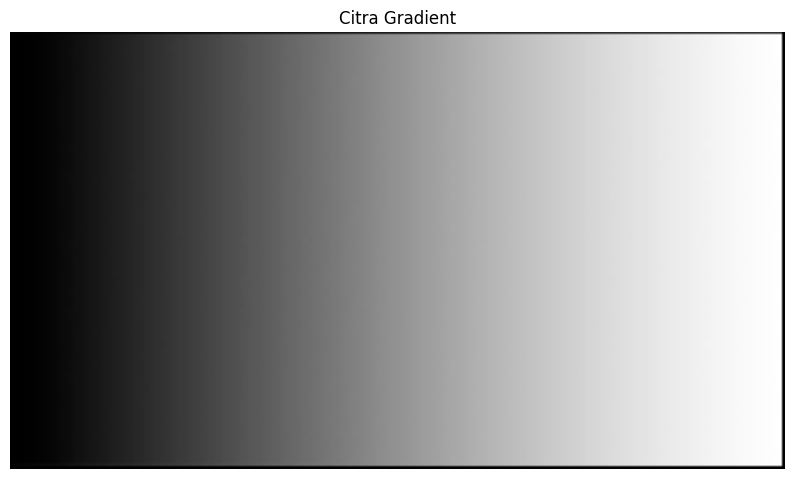

In [7]:
plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(gradient, cv.COLOR_BGR2RGB))
plt.title('Citra Gradient')
plt.axis('off')
plt.show()

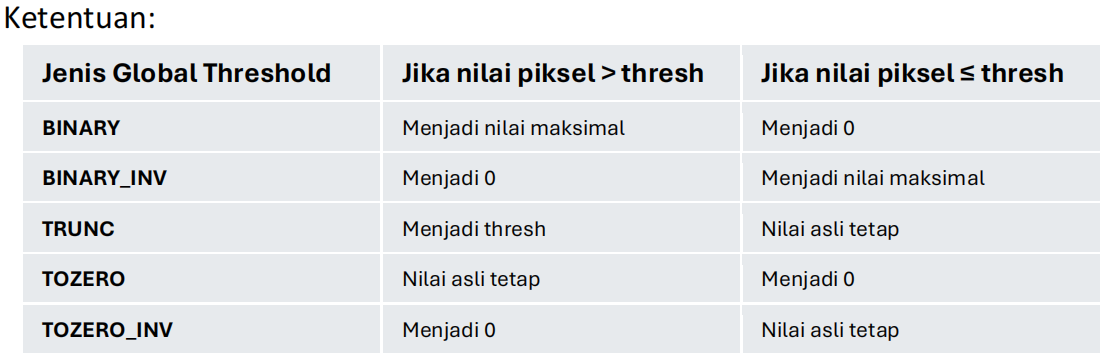

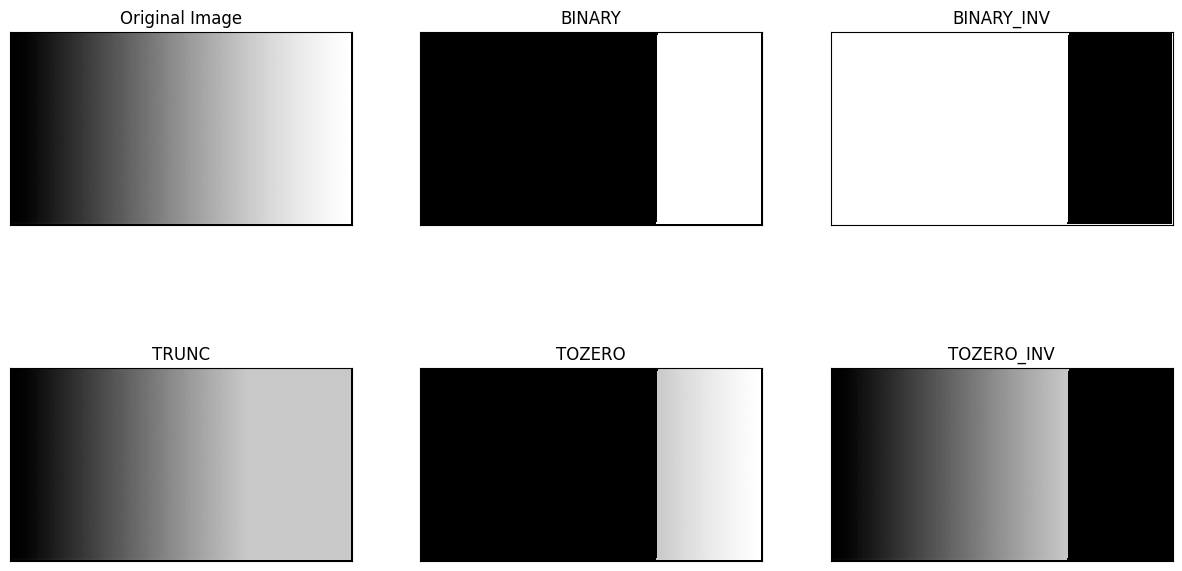

BINARY sama dengan OpenCV: True


In [8]:
img = cv.cvtColor(gradient, cv.COLOR_BGR2GRAY)   # grayscale 1 channel
thresh, maxval = 200, 255

# BINARY     : > thresh -> maxval, selain itu 0
binary     = np.where(img > thresh, maxval, 0).astype(np.uint8)
# BINARY_INV : > thresh -> 0, selain itu maxval
binary_inv = np.where(img > thresh, 0, maxval).astype(np.uint8)
# TRUNC      : > thresh -> thresh, selain itu nilai asli
trunc      = np.where(img > thresh, thresh, img).astype(np.uint8)
# TOZERO     : > thresh -> nilai asli, selain itu 0
tozero     = np.where(img > thresh, img, 0).astype(np.uint8)
# TOZERO_INV : > thresh -> 0, selain itu nilai asli
tozero_inv = np.where(img > thresh, 0, img).astype(np.uint8)

titles = ['Original Image','BINARY','BINARY_INV','TRUNC','TOZERO','TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15,8))
for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i]); plt.xticks([]); plt.yticks([])
plt.show()

# Verifikasi dengan OpenCV (hanya pembanding)
_, ref = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)
print("BINARY sama dengan OpenCV:", np.array_equal(binary, ref))

**4. Buat program Addaptive Threshold : adaptive mean dan adaptive Gaussian tanpa
menggunakan cv.threshold(), cv.adaptiveThreshold(), maupun fungsi filter siap
pakai dengan menggunakan citra Sudoku yang memiliki pencahayaan tidak merata.
Ketentuan: global threshold secara manual dengan ambang 127, ukuran jendela 11 ×
11, C=2, dan sigma=2 untuk Gaussian sehingga menghasilkan tampilan seperti
berikut:**

**a. Baca citra Sudoku**

In [27]:
filename = '/content/drive/MyDrive/PCVK/sudoku-original.jpg.jpeg'
citra = cv.imread(filename)

if citra is None:
    print("Citra sudoku tidak ditemukan!")
else:
    print("Citra sudoku berhasil dibaca")
    print("Ukuran citra :", citra.shape)

Citra sudoku berhasil dibaca
Ukuran citra : (423, 419, 3)


**b. Ubah ke grayscale dan haluskan (median blur manual 5×5)**

In [28]:
# Grayscale
gray0 = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

# Median blur manual 5x5
def median_manual(g, k=5):
    pad = k // 2
    gp = np.pad(g, pad, mode='edge')
    H, W = g.shape
    tumpukan = np.stack([gp[dy:dy+H, dx:dx+W]
                         for dy in range(k) for dx in range(k)], axis=0)
    return np.median(tumpukan, axis=0).astype(np.uint8)

gray = gray0

print("Grayscale:", gray.shape, gray.dtype, "| min =", gray.min(), "max =", gray.max())

Grayscale: (423, 419) uint8 | min = 5 max = 218


**c. Global threshold manual (T = 127) + Adaptive Mean & Adaptive Gaussian manual**

In [30]:
def global_manual(g, t=127):
    return np.where(g > t, 255, 0).astype(np.uint8)

th_global = global_manual(gray, 127)

Ukuran kernel : (11, 11)
Jumlah seluruh kernel = 1.0
Adaptive Mean & Gaussian selesai


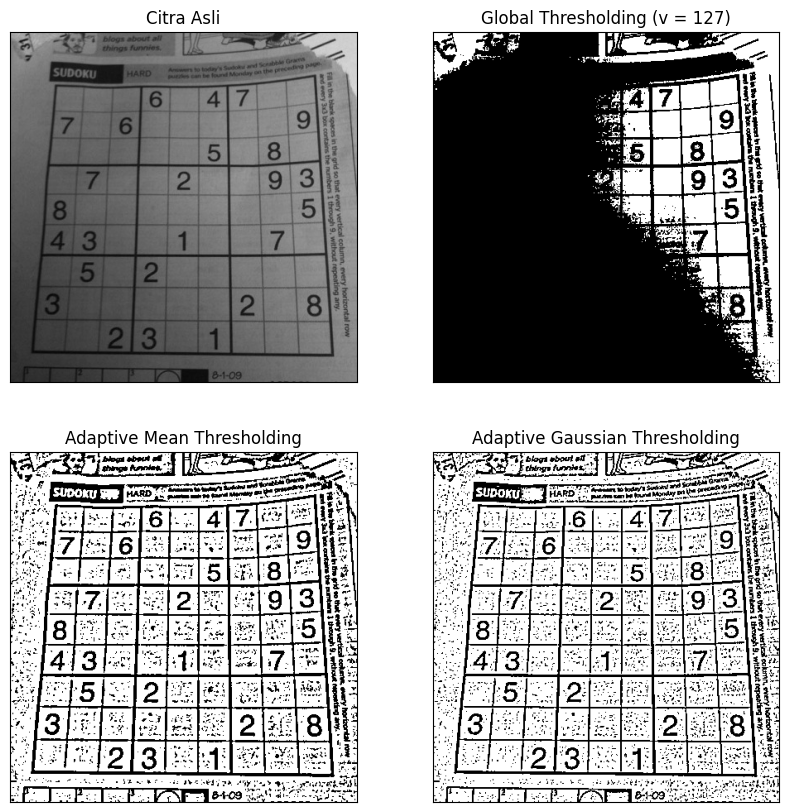

In [32]:
# 1. Hitung rata-rata lokal berbobot (jendela digeser, tanpa fungsi filter siap pakai)
def ambang_lokal(g, kernel):
    b = kernel.shape[0]
    pad = b // 2
    gp = np.pad(g.astype(np.float64), pad, mode='edge')   # replikasi tepi
    H, W = g.shape

    lokal = np.zeros((H, W))
    for dy in range(b):
        for dx in range(b):
            lokal += kernel[dy, dx] * gp[dy:dy+H, dx:dx+W]
    return lokal

# 2. Kernel Gaussian manual
def gaussian_kernel(size=11, sigma=2):
    pusat = size // 2
    ax = np.arange(-pusat, pusat + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()          # normalisasi: jumlah bobot = 1

# 3. Adaptive Mean
def adaptive_mean_manual(g, block_size=11, C=2):
    kernel = np.ones((block_size, block_size)) / (block_size * block_size)
    T = ambang_lokal(g, kernel) - C       # T(x,y) = mean - C
    return np.where(g > T, 255, 0).astype(np.uint8)

# 4. Adaptive Gaussian
def adaptive_gaussian_manual(g, block_size=11, sigma=2, C=2):
    kernel = gaussian_kernel(block_size, sigma)
    T = ambang_lokal(g, kernel) - C       # T(x,y) = mean Gaussian - C
    return np.where(g > T, 255, 0).astype(np.uint8)

# Cek kernel Gaussian
kernel = gaussian_kernel(11, 2)
print("Ukuran kernel :", kernel.shape)
print("Jumlah seluruh kernel =", kernel.sum())

# Jalankan
th_mean  = adaptive_mean_manual(gray, block_size=11, C=2)
th_gauss = adaptive_gaussian_manual(gray, block_size=11, sigma=2, C=2)
print("Adaptive Mean & Gaussian selesai")

titles = ['Citra Asli',
          'Global Thresholding (v = 127)',
          'Adaptive Mean Thresholding',
          'Adaptive Gaussian Thresholding']
hasil = [gray, th_global, th_mean, th_gauss]

plt.figure(figsize=(10, 10))
for i in range(4):
    plt.subplot(2, 2, i+1)
    plt.imshow(hasil[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]); plt.yticks([])
plt.show()

**5. Otsu Thresholding tanpa menggunakan Library**

**a.Tampilkan juga nilai threshold
saat anda gunakan Otsu’s, seperti terlihat pada gambar hasil berikut. (gunakan image
lena_gs_lc2.jpg untuk dibandingkan dengan hasil dengan penggunaan library**

/tmp/ipykernel_835/2283350150.py:26: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
/tmp/ipykernel_835/2283350150.py:27: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)


Threshold Otsu manual = 93


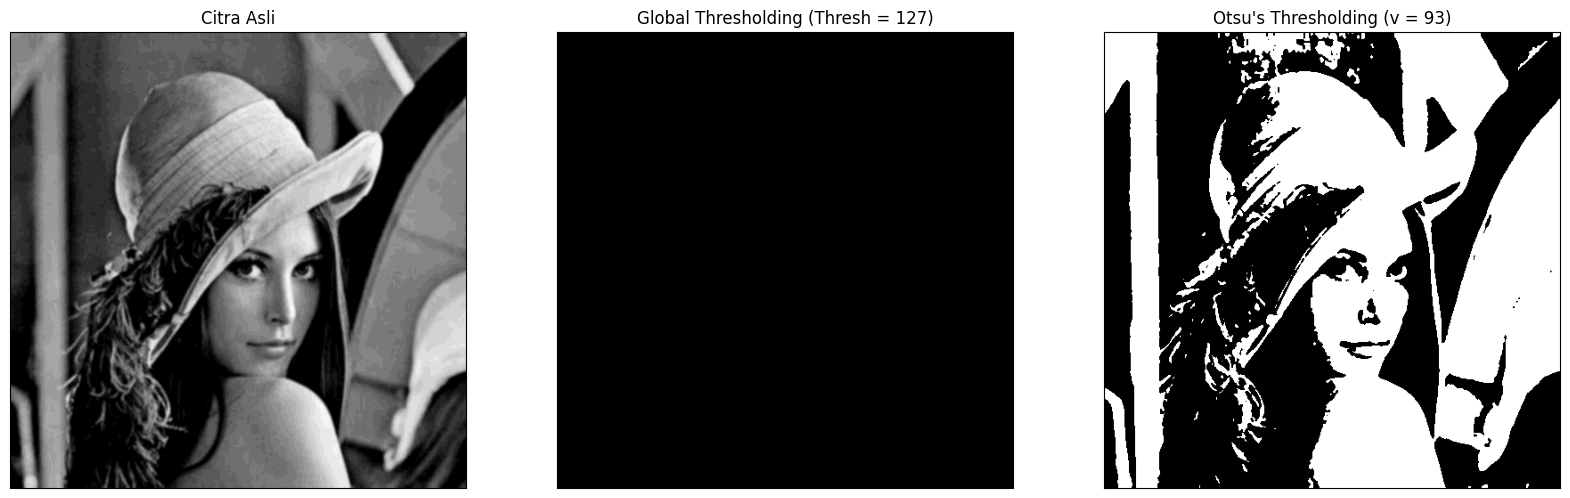

In [45]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca citra
filename = '/content/drive/MyDrive/PCVK/lena_gs_lc2.jpeg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

# 2. Fungsi Otsu Manual
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = gray.copy()
    print("Threshold Otsu manual =", final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0

    return final_img, final_thresh

# 3. Jalankan Otsu manual
otsu_biner, otsu_thresh = otsu(blur)

# 4. Global Threshold sebagai pembanding
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

# 5. Tampilkan hasil
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli',
          'Global Thresholding (Thresh = ' + str(thresh) + ')',
          x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])
plt.show()

In [46]:
ret2, th_lib = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print("Threshold Otsu manual  :", otsu_thresh)
print("Threshold Otsu library :", ret2)

Threshold Otsu manual  : 93
Threshold Otsu library : 92.0


**Pertanyaan: Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam
semuan? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas
(Thresh) supaya gambar Lena ini masih terlihat?
Hasil dengan KTP_Fulan (Bandingkan dengan hasil yang diperoleh)**
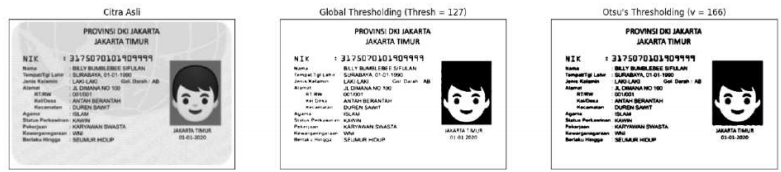

min = 85  max = 108


/tmp/ipykernel_835/2532992062.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0,256])


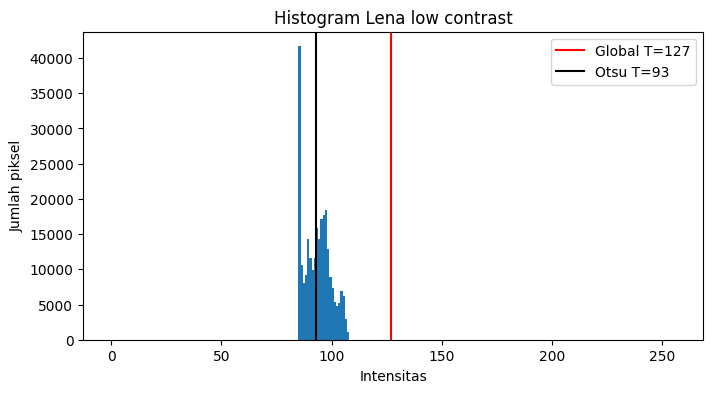

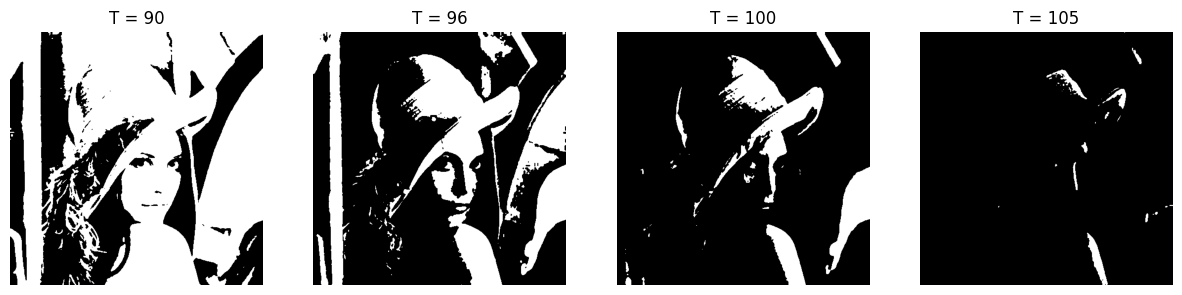

In [47]:
print("min =", blur.min(), " max =", blur.max())

plt.figure(figsize=(8,4))
plt.hist(blur.ravel(), 256, [0,256])
plt.axvline(127, color='red', label='Global T=127')
plt.axvline(otsu_thresh, color='black', label=f'Otsu T={otsu_thresh}')
plt.legend(); plt.title('Histogram Lena low contrast')
plt.xlabel('Intensitas'); plt.ylabel('Jumlah piksel'); plt.show()

plt.figure(figsize=(15,4))
for i, t in enumerate([90, 96, 100, 105]):
    _, r = cv.threshold(blur, t, 255, cv.THRESH_BINARY)
    plt.subplot(1,4,i+1); plt.imshow(r,'gray'); plt.title(f'T = {t}'); plt.axis('off')
plt.show()

**Penjelasan:** Hasil Binary Thresholding pada citra lena_gs_lc2.jpeg menjadi hitam seluruhnya karena citra ini merupakan citra low contrast, dengan rentang intensitas piksel hanya 85–108. Karena threshold yang digunakan adalah T = 127, sedangkan seluruh piksel bernilai di bawah 127, maka tidak ada piksel yang memenuhi syarat piksel > T. Akibatnya, semua piksel diubah menjadi 0 (hitam).

Hal ini dapat dibuktikan melalui histogram, di mana seluruh distribusi piksel berada di sebelah kiri garis T = 127. Agar citra Lena masih terlihat, nilai T harus berada di dalam rentang histogram, yaitu sekitar T = 93 (nilai Otsu otomatis) atau T = 95–100.

Sebagai perbandingan, pada citra KTP Fulan yang memiliki kontras lebih baik (histogram bimodal), global threshold T = 127 masih dapat digunakan, meskipun hasil Otsu (T = 166) memberikan segmentasi yang lebih optimal. Perbedaan ini menunjukkan bahwa pemilihan nilai T sangat bergantung pada distribusi intensitas citra.

**b.  Kemudian coba dengan image KTP sendiri agar terlihat beda antara hasil otsu’s
dengan global threshold biasa)**

Ukuran citra KTP : (458, 694, 3)
Threshold Otsu manual = 166
Threshold Otsu KTP (manual) : 166
Threshold Otsu KTP (library): 165.0


/tmp/ipykernel_835/2283350150.py:26: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)


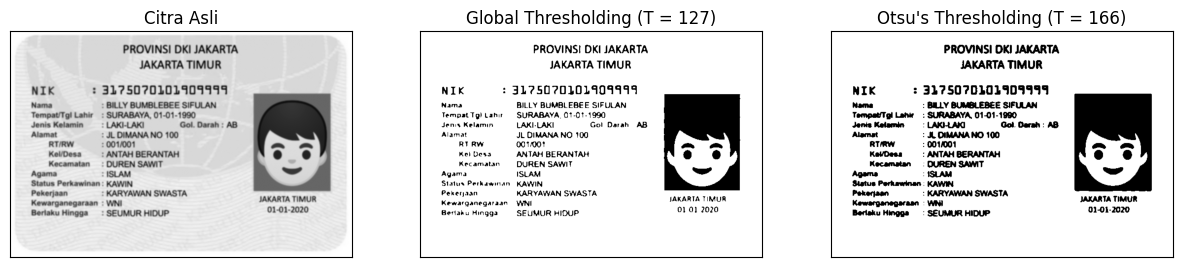

In [49]:
# 1. Baca citra KTP
filename = '/content/drive/MyDrive/PCVK/ktp_fulan.jpg'
ktp = cv.imread(filename)

if ktp is None:
    raise FileNotFoundError(f"File tidak ditemukan: {filename}")

print("Ukuran citra KTP :", ktp.shape)

# 2. Konversi ke grayscale dan haluskan
ktp_gray = cv.cvtColor(ktp, cv.COLOR_BGR2GRAY)
ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)

# 3. Global Threshold manual (T = 127)
thresh = 127
_, ktp_global = cv.threshold(ktp_blur, thresh, 255, cv.THRESH_BINARY)

# 4. Otsu Threshold (manual)
ktp_otsu_biner, ktp_otsu_thresh = otsu(ktp_blur)
print("Threshold Otsu KTP (manual) :", ktp_otsu_thresh)

# 5. Otsu Threshold (library OpenCV) sebagai pembanding
ret_otsu, ktp_otsu_lib = cv.threshold(
    ktp_blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU
)
print("Threshold Otsu KTP (library):", ret_otsu)

# 6. Tampilkan hasil
titles = [
    'Citra Asli',
    'Global Thresholding (T = 127)',
    f"Otsu's Thresholding (T = {ktp_otsu_thresh})"
]
citra_ktp = [ktp_blur, ktp_global, ktp_otsu_biner]

plt.figure(figsize=(15, 5))
for i in range(len(citra_ktp)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_ktp[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

**6. Segmentasi Berbasis Region (data.coins)**

**a. Lakukan Segmentasi Berbasis Region pada citra data.coins() dari skimage.**

Ukuran citra coins : (303, 384)


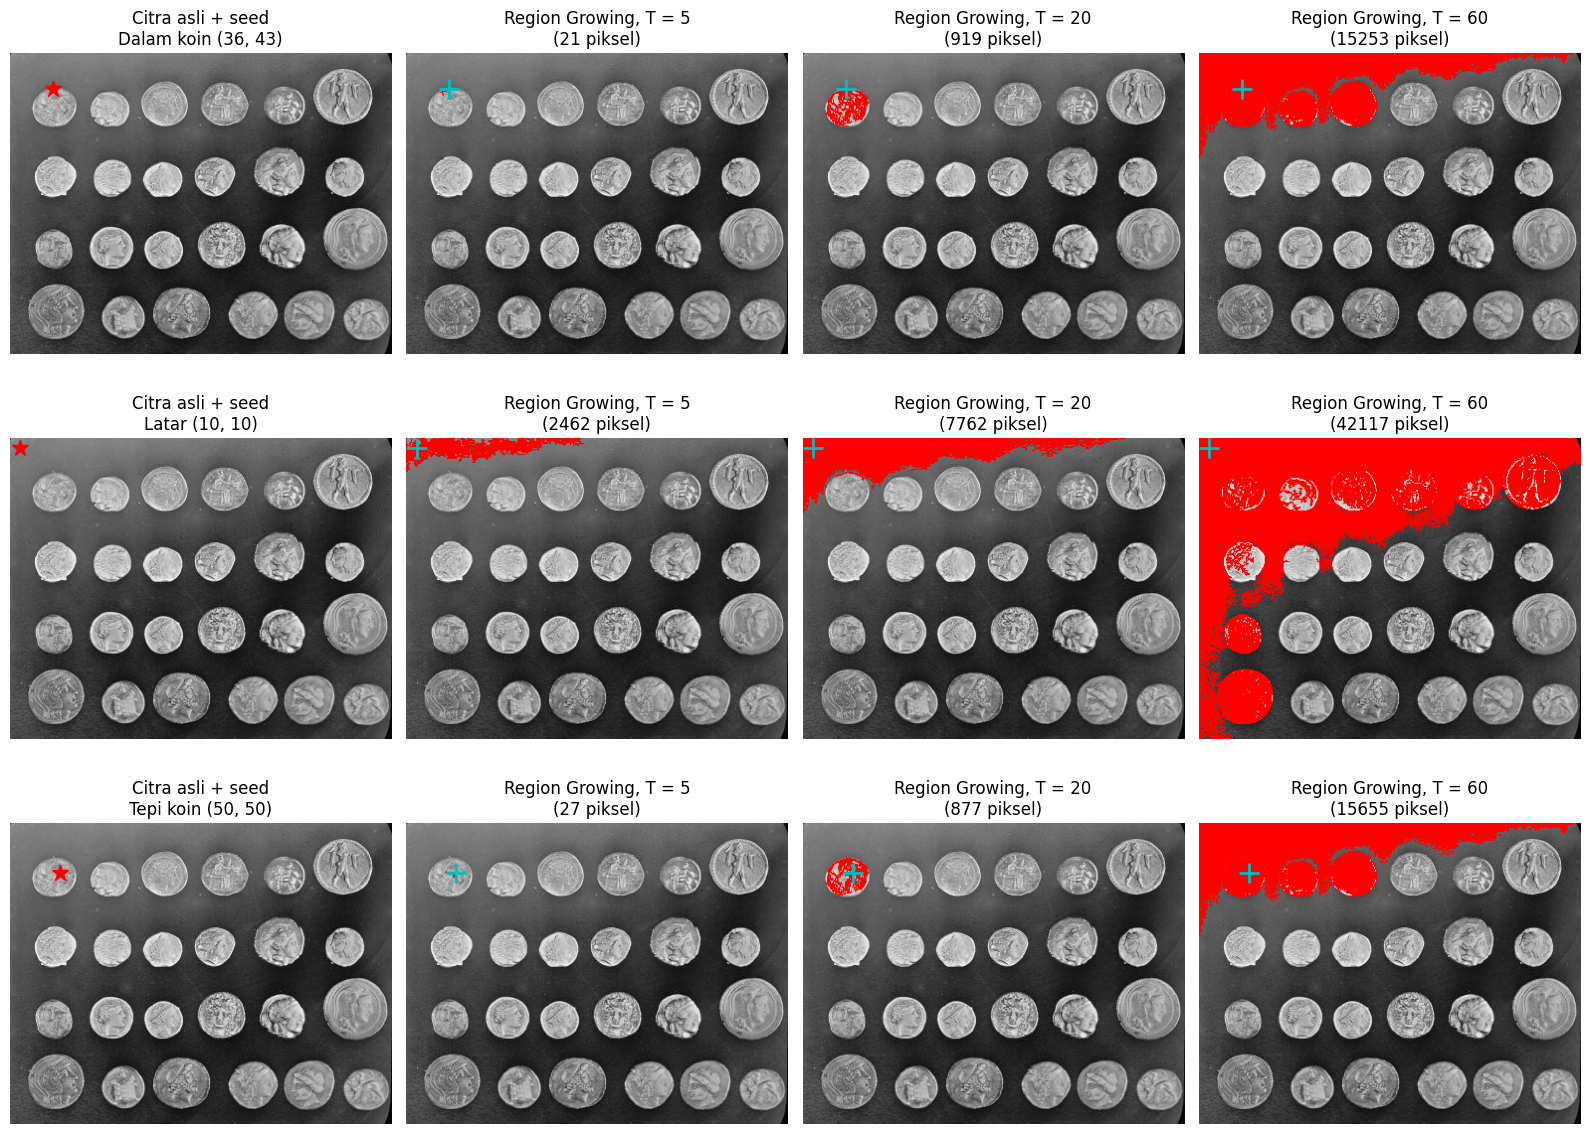

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from collections import deque

# 1. Ambil citra coins
img = data.coins()
print("Ukuran citra coins :", img.shape)

# 2. Tentukan 3 seed: (baris, kolom)
seeds = [
    (36, 43),    # di dalam koin
    (10, 10),    # di latar
    (50, 50),    # di tepi koin
]
names = ['Dalam koin', 'Latar', 'Tepi koin']

# 3. Fungsi Region Growing manual
def region_growing(gray, seed, T):
    H, W = gray.shape
    visited = np.zeros((H, W), dtype=bool)
    region  = np.zeros((H, W), dtype=bool)

    seed_val = gray[seed]
    queue = deque([seed])
    visited[seed] = True

    while queue:
        y, x = queue.popleft()
        region[y, x] = True

        for dy, dx in [(-1,0), (1,0), (0,-1), (0,1)]:
            ny, nx = y + dy, x + dx
            if 0 <= ny < H and 0 <= nx < W and not visited[ny, nx]:
                if abs(int(gray[ny, nx]) - int(seed_val)) <= T:
                    visited[ny, nx] = True
                    queue.append((ny, nx))

    return region

# 4. Jalankan dan tampilkan grid 3x4 (citra asli + 3 nilai T)
T_values = [5, 20, 60]
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i, (seed, nm) in enumerate(zip(seeds, names)):
    # Kolom 1: citra asli + seed
    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].plot(seed[1], seed[0], 'r*', markersize=12)
    axes[i, 0].set_title(f"Citra asli + seed\n{nm} {seed}")
    axes[i, 0].axis('off')

    # Kolom 2-4: hasil region growing untuk setiap T
    for j, T in enumerate(T_values):
        region = region_growing(img, seed, T)
        jumlah = int(region.sum())

        overlay = np.stack([img] * 3, axis=-1)
        overlay[region] = [255, 0, 0]

        axes[i, j+1].imshow(overlay)
        axes[i, j+1].plot(seed[1], seed[0], 'c+', markersize=14,
                          markeredgewidth=2)
        axes[i, j+1].set_title(f"Region Growing, T = {T}\n({jumlah} piksel)")
        axes[i, j+1].axis('off')

plt.tight_layout()
plt.show()

**b. Gunakan skimage.segmentation.flood(). Fungsi ini menghasilkan mask region dari
seed dengan menerima piksel yang terhubung dan intensitasnya berada dalam
toleransi terhadap intensitas seed.**

Seed (baris,kolom): (121, 63) | intensitas seed: 224 | piksel region: 177


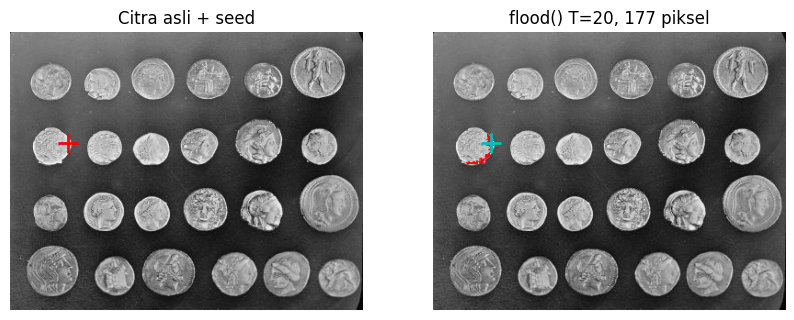

In [59]:
seed = (121, 63)
region = flood(
    gray_c,
    seed_point=seed,
    tolerance=20,
    connectivity=1
)

base = np.stack([gray_c]*3, axis=-1)
overlay = base.copy()
overlay[region] = [255, 0, 0]             # region hasil flood diberi warna merah

print(f"Seed (baris,kolom): {seed} | intensitas seed: {gray_c[seed]} | piksel region: {region.sum()}")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(gray_c, 'gray')
plt.plot(seed[1], seed[0], 'r+', markersize=14, markeredgewidth=2)
plt.title('Citra asli + seed'); plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(overlay)
plt.plot(seed[1], seed[0], 'c+', markersize=14, markeredgewidth=2)
plt.title(f'flood() T=20, {region.sum()} piksel'); plt.axis('off')
plt.show()

Seed (36, 43) | T=5 | piksel: 21
Seed (36, 43) | T=20 | piksel: 919
Seed (36, 43) | T=60 | piksel: 15253
Seed (10, 10) | T=5 | piksel: 2462
Seed (10, 10) | T=20 | piksel: 7762
Seed (10, 10) | T=60 | piksel: 42117
Seed (50, 50) | T=5 | piksel: 27
Seed (50, 50) | T=20 | piksel: 877
Seed (50, 50) | T=60 | piksel: 15655


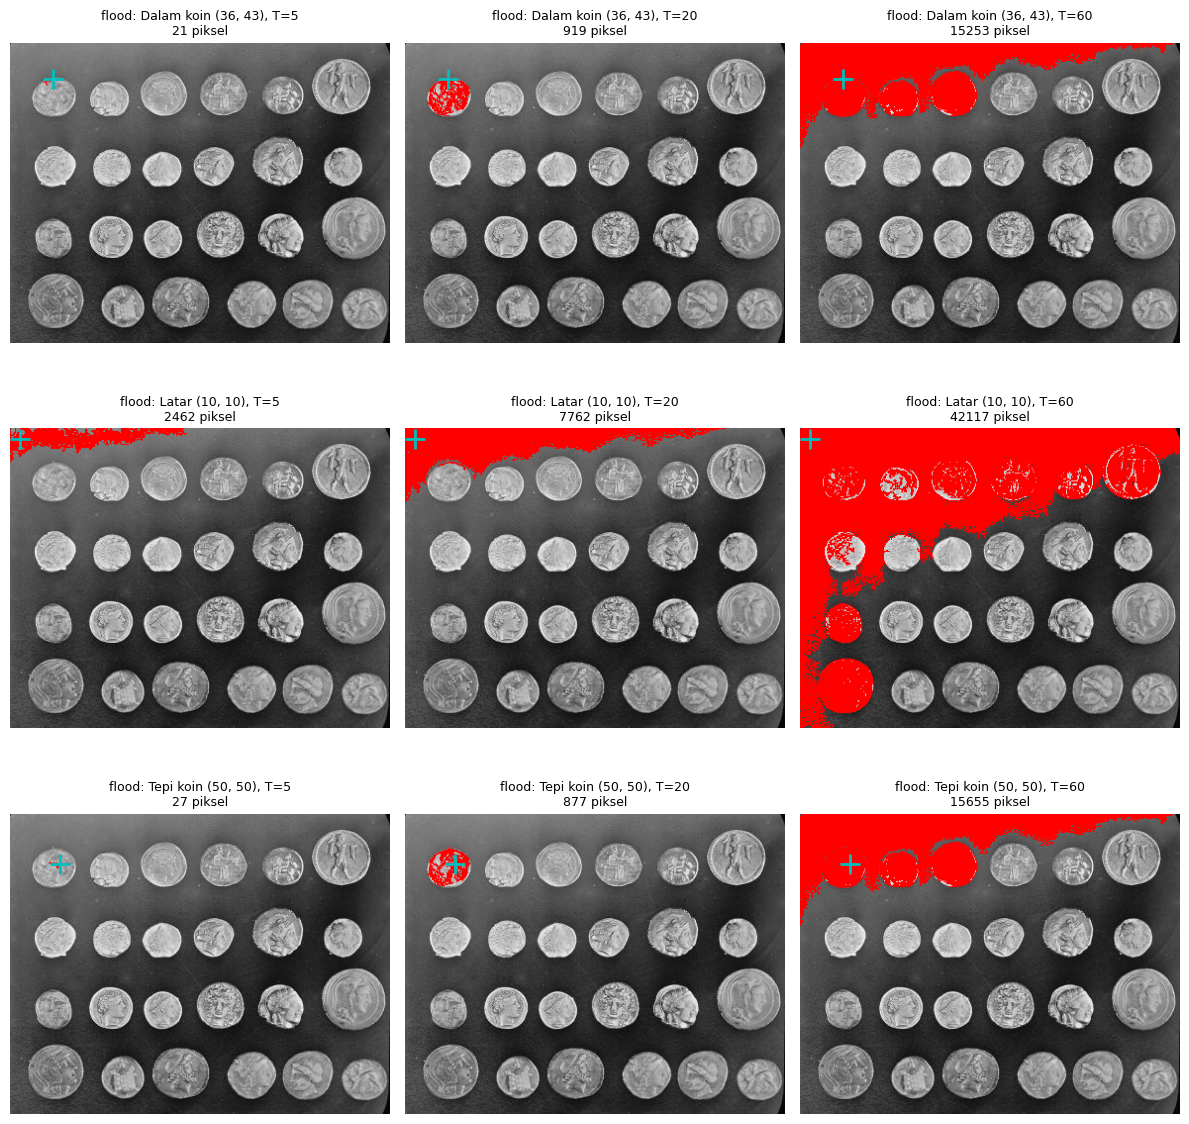

In [63]:
# 1. Ambil citra coins
ase = np.stack([gray_c]*3, axis=-1)

plt.figure(figsize=(12,12))
k = 1
for s, nm in zip(seeds, names):
    for T in Ts:
        r = flood(gray_c, seed_point=s, tolerance=T, connectivity=1)

        ov = base.copy()
        ov[r] = [255, 0, 0]

        plt.subplot(3,3,k); k += 1
        plt.imshow(ov)
        plt.plot(s[1], s[0], 'c+', markersize=14, markeredgewidth=2)
        plt.title(f'flood: {nm} {s}, T={T}\n{r.sum()} piksel', fontsize=9)
        plt.axis('off')
        print(f"Seed {s} | T={T} | piksel: {r.sum()}")
plt.tight_layout()
plt.show()

**7. Lakukan segmentasi warna pada image ktp_fulan.jpg , munculkan hanya warna yang
biru saja. (Petunjuk: anda dapat gunakan K-Means untuk menampilkan hanya warna
tertentu saja).
Rentang mencakup biru muda kebiruan pada latar KTP (dengan warna HSV):
kelompok_biru = np.where( (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)**

**Baca Citra KTP**

Ukuran citra KTP : (458, 694, 3)


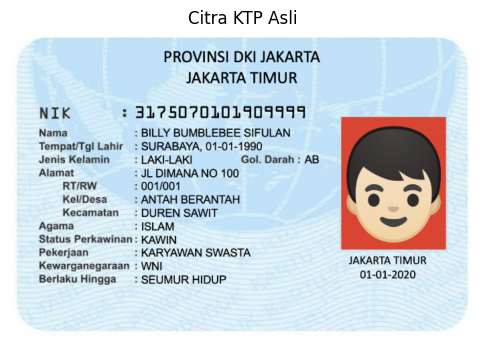

In [66]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/drive/MyDrive/PCVK/ktp_fulan.jpg'
ktp = cv.imread(filename)

if ktp is None:
    raise FileNotFoundError(f"File tidak ditemukan: {filename}")

print("Ukuran citra KTP :", ktp.shape)

# Konversi BGR ke RGB untuk ditampilkan dengan matplotlib
rgb = cv.cvtColor(ktp, cv.COLOR_BGR2RGB)

plt.figure(figsize=(6, 4))
plt.imshow(rgb)
plt.title('Citra KTP Asli')
plt.axis('off')
plt.show()

**Cara A: Mask Biru dengan HSV**

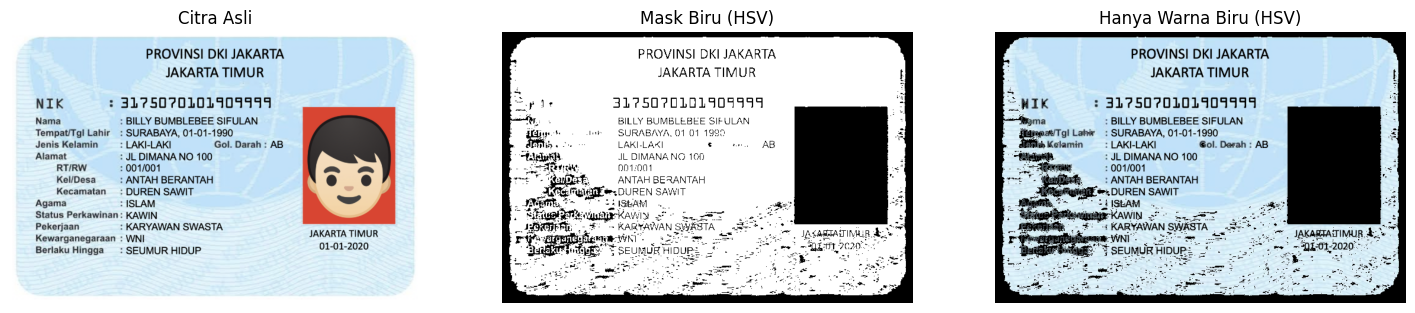

In [69]:
hasil_hsv = np.zeros_like(ktp)          # latar HITAM
hasil_hsv[biru] = ktp[biru]             # hanya piksel biru dipertahankan

plt.figure(figsize=(18,5))
plt.subplot(1,3,1); plt.imshow(cv.cvtColor(ktp, cv.COLOR_BGR2RGB))
plt.title('Citra Asli'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(biru, 'gray')
plt.title('Mask Biru (HSV)'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(cv.cvtColor(hasil_hsv, cv.COLOR_BGR2RGB))
plt.title('Hanya Warna Biru (HSV)'); plt.axis('off')
plt.show()

**Cara B: K-Means Clustering (K=8)**

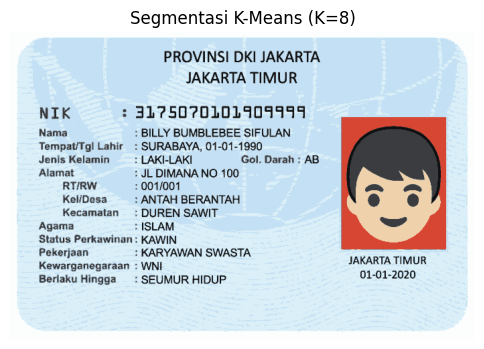

Pusat cluster (R, G, B):
[[135 147 155]
 [218 239 248]
 [ 15  16  17]
 [215  70  51]
 [195 224 244]
 [239 210 172]
 [252 254 254]
 [ 59  60  63]]


In [68]:
from sklearn.cluster import KMeans

Z = np.float32(rgb.reshape((-1, 3)))

k = 8
rng = np.random.default_rng(42)
sample = Z[rng.choice(len(Z), size=min(50000, len(Z)), replace=False)]

# Jalankan K-Means
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(sample)
labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)

# Bentuk kembali menjadi citra
segmented = centers[labels].reshape(rgb.shape)

# Tampilkan hasil segmentasi K-Means
plt.figure(figsize=(6, 4))
plt.imshow(segmented)
plt.title(f'Segmentasi K-Means (K={k})')
plt.axis('off')
plt.show()

# Tampilkan pusat cluster
print("Pusat cluster (R, G, B):")
print(centers)

**Filter Cluster Biru**

Cluster biru: [0, 1, 4]
  cluster 0 | warna pusat (RGB): [135 147 155]
  cluster 1 | warna pusat (RGB): [218 239 248]
  cluster 4 | warna pusat (RGB): [195 224 244]


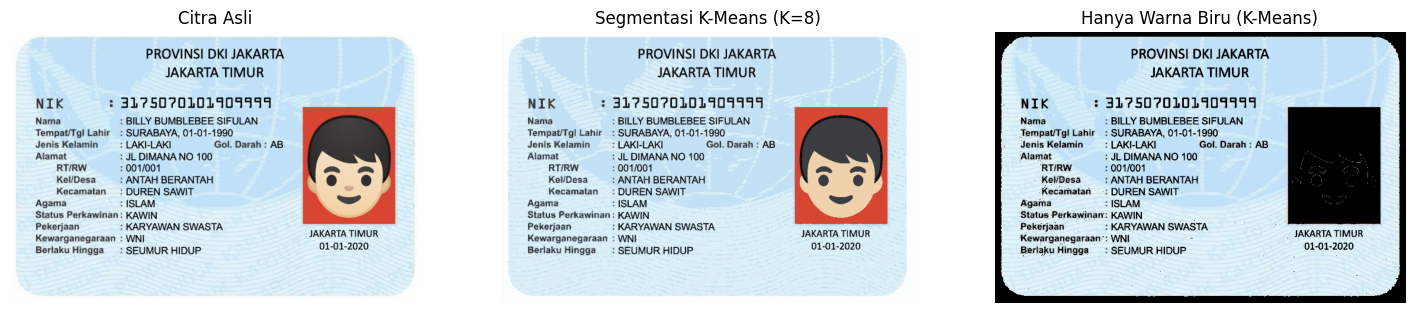

In [72]:
pusat_hsv = cv.cvtColor(centers.reshape(-1,1,3), cv.COLOR_RGB2HSV).reshape(-1,3)
idx_biru = [i for i, (h, s, v) in enumerate(pusat_hsv)
            if 85 <= h <= 130 and s >= 25 and v >= 40]

# cadangan: kalau tidak ada yang memenuhi, ambil cluster dengan komponen B paling dominan
if not idx_biru:
    skor_biru = centers[:,2].astype(int) - (centers[:,0].astype(int) + centers[:,1].astype(int)) / 2
    idx_biru = [int(np.argmax(skor_biru))]

print("Cluster biru:", idx_biru)
for i in idx_biru:
    print(f"  cluster {i} | warna pusat (RGB): {centers[i]}")

mask_km = np.isin(labels, idx_biru).reshape(rgb.shape[:2])
hasil_km = np.zeros_like(rgb)
hasil_km[mask_km] = rgb[mask_km]

plt.figure(figsize=(18,5))
plt.subplot(1,3,1); plt.imshow(rgb)
plt.title('Citra Asli'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(segmented)
plt.title(f'Segmentasi K-Means (K={k})'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(hasil_km)
plt.title('Hanya Warna Biru (K-Means)'); plt.axis('off')
plt.show()

## **D2. Tugas Kelompok**

**Proses konversi gambar KTP menjadi teks yang dapat mengenali tulisan.
Proses konversi gambar menjadi teks dikenal dengan istilah OCR (Optical Character Recognition)
adalah teknologi untuk mengenali tulisan pada gambar dan mengubahnya menjadi teks digital
yang dapat disalin, diedit, atau diolah.**

**Tesseract merupakan mesin OCR, sedangkan pytesseract digunakan untuk mengaksesnya
melalui Python. Ketepatan pembacaan dipengaruhi oleh kejelasan tulisan, pencahayaan, ukuran
huruf, dan latar belakang gambar. Langkah awal adalah melakukan Instal Tesseract dan model
bahasa Indonesia.**

**Install Tesseract & Bahasa Indonesia**

In [73]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

# Cek bahasa yang tersedia (harus ada 'ind' dan 'eng')
!tesseract --list-langs

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...
List of available languages in "/usr/share/tesseract-ocr/5/tessdata/" (3):
eng
ind
osd


**Import Library & Konfigurasi**

In [84]:
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
from difflib import SequenceMatcher
from IPython.display import display

BASE = '/content/drive/MyDrive/PCVK'

# ---- Pengaturan SAMA untuk ketiga citra ----
LANG     = 'ind'
PSM      = 6
CONF_MIN = 60
LEBAR    = 1600
AD_BLOCK = 51
AD_C     = 15

# ---- Data KTP pribadi ----
ANGGOTA = {
    'Saya': {
        'file': f'{BASE}/ktp.jpeg',
'acuan': [
    'PROVINSI', 'JAWA TIMUR', 'KOTA MALANG', 'NIK',
    'Nama', 'PEREMPUAN', 'ISLAM', 'BELUM KAWIN',
    'PELAJAR/MAHASISWA', 'SEUMUR HIDUP'
]
    }
}

METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']
KOLOM  = {
    'Berwarna asli'      : 'OCR citra berwarna',
    'Segmentasi Otsu'    : 'OCR Otsu',
    'Segmentasi Adaptive': 'OCR Adaptive'
}

**Fungsi-Fungsi Utama**

In [85]:
import os

def muat_citra(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"File tidak ditemukan: {path}")
    img = cv.imread(path)
    if img is None:
        raise ValueError(f"cv.imread gagal membaca: {path}")
    return img


def siapkan_tiga_citra(path):
    """Satu citra KTP → tiga versi dengan ukuran sama:
       berwarna, Otsu, Adaptive."""
    bgr = muat_citra(path)
    h, w = bgr.shape[:2]

    # Resize ke lebar LEBAR
    bgr = cv.resize(bgr, (LEBAR, int(h * LEBAR / w)),
                    interpolation=cv.INTER_CUBIC)

    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)   # grayscale dulu

    _, otsu = cv.threshold(gray, 0, 255,
                           cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(gray, 255,
                                    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY,
                                    AD_BLOCK, AD_C)
    return {
        'Berwarna asli'      : bgr,
        'Segmentasi Otsu'    : otsu,
        'Segmentasi Adaptive': adaptive
    }


def jalankan_ocr(img):
    """image_to_string + image_to_data, bahasa & psm sama."""
    img_ocr = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    cfg = f'--oem 3 --psm {PSM}'
    teks = pytesseract.image_to_string(img_ocr, lang=LANG, config=cfg)
    data = pytesseract.image_to_data(img_ocr, lang=LANG, config=cfg,
                                     output_type=Output.DICT)
    return teks, data


def rata_conf(data):
    """Rata-rata confidence seluruh kata yang dikenali."""
    c = [float(cf) for cf, t in zip(data['conf'], data['text'])
         if t.strip() and float(cf) >= 0]
    return float(np.mean(c)) if c else 0.0


def gambar_kotak(img, data):
    """Kotak hijau pada kata dengan confidence > CONF_MIN."""
    kanvas = img.copy() if img.ndim == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    n = 0
    for i, t in enumerate(data['text']):
        if t.strip() and any(ch.isalnum() for ch in t) and \
           float(data['conf'][i]) > CONF_MIN:
            x, y, w, h = (data['left'][i], data['top'][i],
                          data['width'][i], data['height'][i])
            cv.rectangle(kanvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
            n += 1
    return kanvas, n


def bersih(t):
    return t.strip('''.,;:|_[](){}'"''')


def baca_item(item, teks):
    """Cari bagian teks OCR yang paling mirip dengan item acuan."""
    tok = [bersih(t) for t in teks.split() if bersih(t)]
    n, target = len(item.split()), item.upper()
    terbaik, skor = '', 0.0
    for k in range(max(1, n - 1), n + 3):
        for i in range(len(tok) - k + 1):
            cand = ' '.join(tok[i:i + k]).upper()
            s = SequenceMatcher(None, cand, target).ratio()
            if s > skor:
                terbaik, skor = cand, s
    if skor == 1.0:
        return item, True
    if skor >= 0.5:
        return terbaik, False
    return ('tidak terbaca'), False


def jenis_salah(item, baca):
    if baca == '(tidak terbaca)':
        return 'teks tidak terbaca'
    a, b = item.upper(), baca.upper()
    if a in b:
        return 'kata menyatu dengan teks lain'
    if len(a) == len(b):
        beda = [f'{x}->{y}' for x, y in zip(a, b) if x != y]
        return 'huruf tertukar (' + ', '.join(beda) + ')'
    return 'huruf hilang' if len(b) < len(a) else 'huruf tambahan/salah baca'

**Jalankan OCR untuk KTP Anda**

Saya selesai | ukuran citra: (1023, 1600)

Tiga citra untuk dibandingkan: Saya


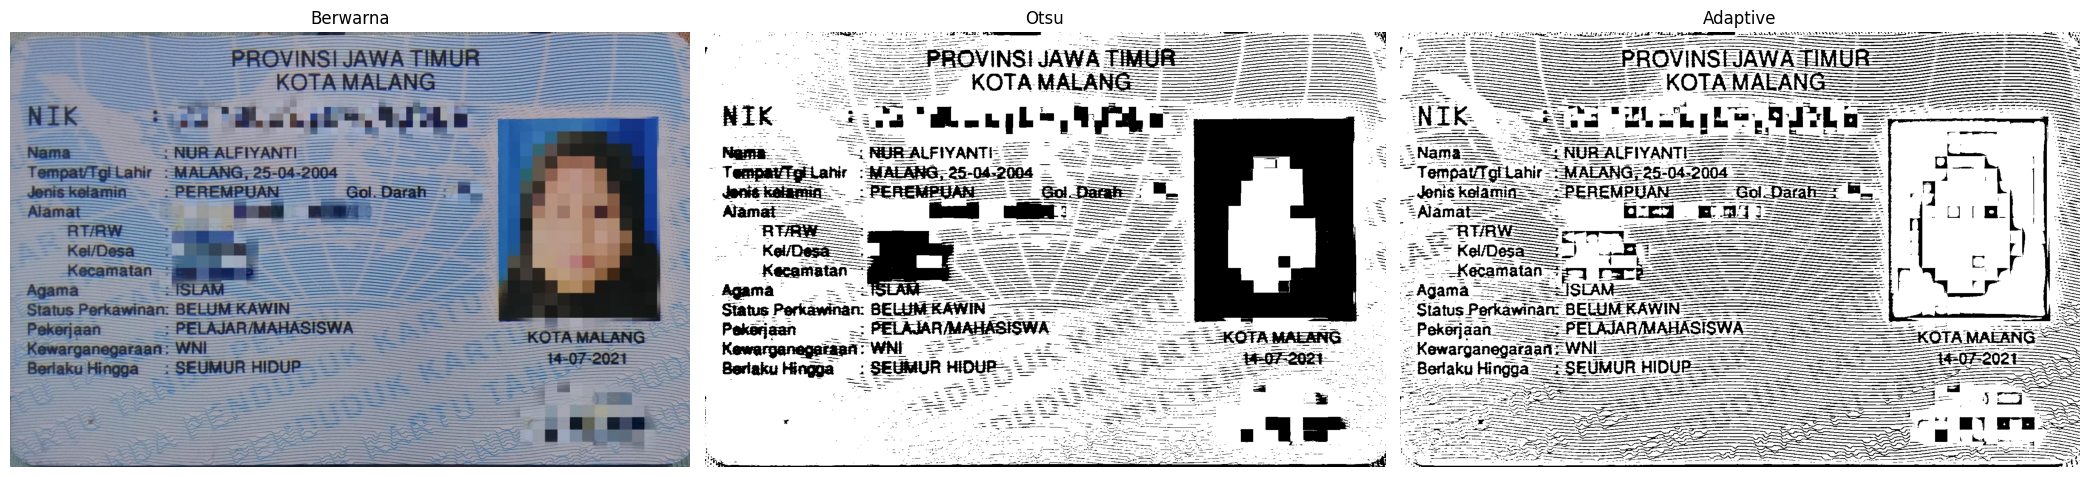

In [86]:
HASIL = {}
for nama, info in ANGGOTA.items():
    citra = siapkan_tiga_citra(info['file'])
    HASIL[nama] = {}
    for m in METODE:
        teks, data = jalankan_ocr(citra[m])
        kotak, n_kotak = gambar_kotak(citra[m], data)

        bacaan = [baca_item(it, teks) for it in info['acuan']]
        HASIL[nama][m] = {
            'teks': teks, 'data': data,
            'kotak': kotak, 'n_kotak': n_kotak,
            'baca': [b for b, _ in bacaan],
            'cocok': [c for _, c in bacaan],
            'conf': rata_conf(data)
        }
    print(f"{nama} selesai | ukuran citra: {citra['Berwarna asli'].shape[:2]}")

# ---- Tampilkan 3 citra yang dibandingkan ----
LABEL = {'Berwarna asli': 'Berwarna',
         'Segmentasi Otsu': 'Otsu',
         'Segmentasi Adaptive': 'Adaptive'}

for nama, info in ANGGOTA.items():
    citra = siapkan_tiga_citra(info['file'])
    print(f"\nTiga citra untuk dibandingkan: {nama}")
    fig, ax = plt.subplots(1, 3, figsize=(21, 5))
    for a, m in zip(ax, METODE):
        img = citra[m]
        if img.ndim == 3:
            a.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        else:
            a.imshow(img, cmap='gray', vmin=0, vmax=255)
        a.set_title(LABEL[m])
        a.axis('off')
    plt.tight_layout()
    plt.show()

Hasil Pembacaan Teks: Saya


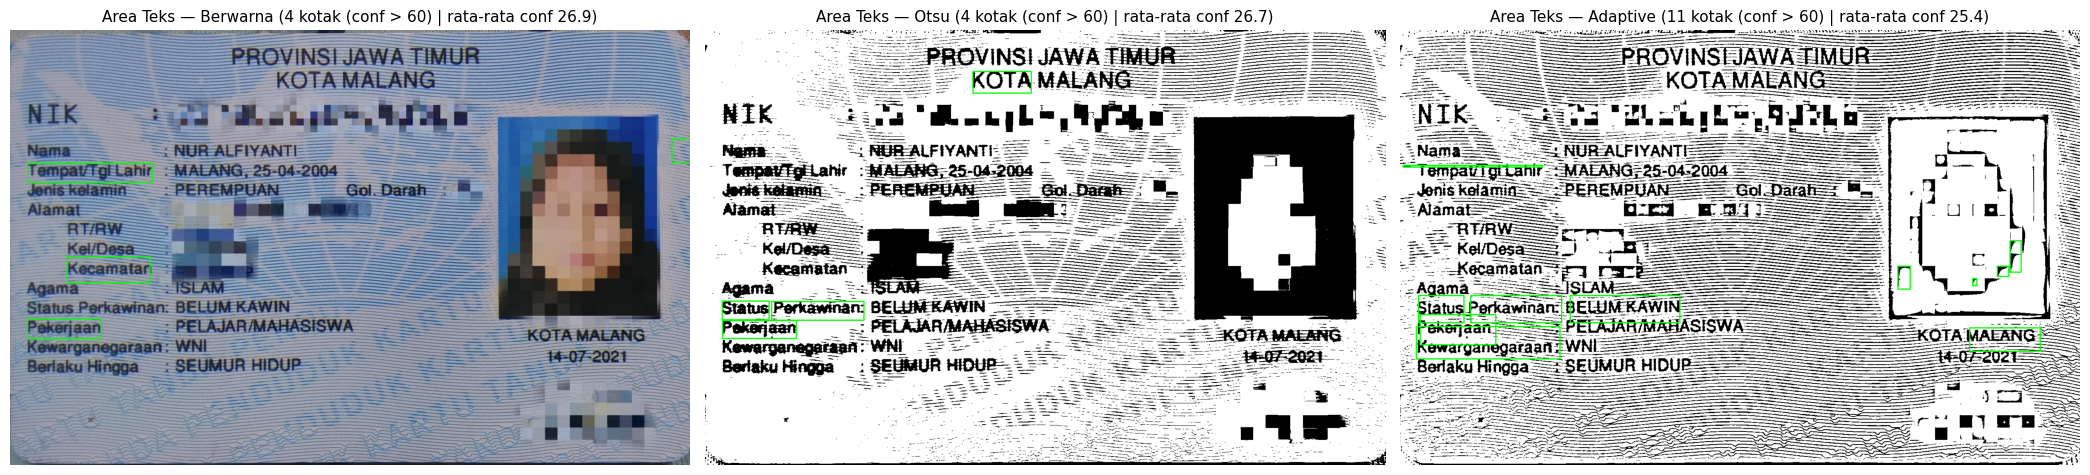

In [87]:
for nama in ANGGOTA:
    print(f"Hasil Pembacaan Teks: {nama}")
    fig, ax = plt.subplots(1, 3, figsize=(21, 5))
    for a, m in zip(ax, METODE):
        h = HASIL[nama][m]
        a.imshow(cv.cvtColor(h['kotak'], cv.COLOR_BGR2RGB))
        a.set_title(f"Area Teks — {LABEL[m]} "
                    f"({h['n_kotak']} kotak (conf > {CONF_MIN}) | "
                    f"rata-rata conf {h['conf']:.1f})", fontsize=11)
        a.axis('off')
    plt.tight_layout()
    plt.show()

**Tabel Perbandingan 10 Item**

In [88]:
for nama, info in ANGGOTA.items():
    tabel = pd.DataFrame({'No.': range(1, len(info['acuan']) + 1),
                          'Teks sebenarnya': info['acuan']})

    gaya = pd.DataFrame('', index=range(len(info['acuan'])),
                        columns=['Teks sebenarnya'] + list(KOLOM.values()))
    for m, kol in KOLOM.items():
        tabel[kol] = HASIL[nama][m]['baca']
        gaya[kol] = ['background-color:#c6f7c5' if ok else
                     'background-color:#f7c5c5'
                     for ok in HASIL[nama][m]['cocok']]
    tabel = tabel.set_index('No.')
    gaya.index = tabel.index

    print(f"=== Tabel perbandingan {nama} "
          f"(hijau = cocok, merah = tidak cocok) ===")
    display(tabel.style.apply(lambda _: gaya, axis=None))

=== Tabel perbandingan Saya (hijau = cocok, merah = tidak cocok) ===


,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
No.,,,,
1,PROVINSI,tidak terbaca,PROVINSIJAWA,PROVINSHAWA
2,JAWA TIMUR,tidak terbaca,PROVINSIJAWA TIMUR”,AKA RI
3,KOTA MALANG,FAMALANG,KOTA MALANG,KOTAMALANGE
4,NIK,tidak terbaca,NIK,NIK
5,Nama,Nama,Nama,2NAMA-
6,PEREMPUAN,PEKERJAAN,PEREMPUAN,PEKERJAAN
7,ISLAM,IA,ALAMAT,SISTAME—
8,BELUM KAWIN,tidak terbaca,BELUMKAWIN,BELUMKAWIN
9,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,PELAJAR/MAHASISWA,PELAJAR/MAHASISWAE


In [89]:
baris_gabungan = []
for nama, info in ANGGOTA.items():
    total = len(info['acuan'])
    baris = []
    for m in METODE:
        h = HASIL[nama][m]
        tepat = sum(h['cocok'])
        baris.append({
            'Citra masukan OCR'   : m,
            'Item terbaca tepat'  : f'{tepat} dari {total}',
            'Kecocokan (%)'       : round(100 * tepat / total, 1),
            'Rata-rata confidence': round(h['conf'], 1),
            'Kotak hijau (conf > 60)': h['n_kotak']
        })
    print(f"=== Ringkasan {nama} ===")
    display(pd.DataFrame(baris).set_index('Citra masukan OCR'))

    # Gabungan seluruh anggota
    for m in METODE:
        tepat = sum(sum(HASIL[n][m]['cocok']) for n in ANGGOTA)
        total = sum(len(ANGGOTA[n]['acuan']) for n in ANGGOTA)
        conf  = np.mean([HASIL[n][m]['conf'] for n in ANGGOTA])
        baris_gabungan.append({
            'Citra masukan OCR': m,
            'Item terbaca tepat': f'{tepat} dari {total}',
            'Kecocokan (%)': round(100 * tepat / total, 1),
            'Rata-rata confidence': round(float(conf), 1)
        })

GAB = pd.DataFrame(baris_gabungan).set_index('Citra masukan OCR')
print("=== Ringkasan GABUNGAN seluruh anggota ===")
display(GAB)

=== Ringkasan Saya ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence,Kotak hijau (conf > 60)
Citra masukan OCR,,,,
Berwarna asli,2 dari 10,20.0,26.9,4
Segmentasi Otsu,5 dari 10,50.0,26.7,4
Segmentasi Adaptive,1 dari 10,10.0,25.4,11


=== Ringkasan GABUNGAN seluruh anggota ===


,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
Citra masukan OCR,,,
Berwarna asli,2 dari 10,20.0,26.9
Segmentasi Otsu,5 dari 10,50.0,26.7
Segmentasi Adaptive,1 dari 10,10.0,25.4


### Ringkasan Hasil OCR (1 KTP - Individu)

| Citra masukan OCR | Item terbaca tepat | Kecocokan (%) | Rata-rata confidence | Kotak hijau (conf > 60) |
|---|---|---|---|---|
| Berwarna asli | 2 dari 10 | 20,0% | 26,9 | 4 |
| Segmentasi Otsu | 5 dari 10 | 50,0% | 26,7 | 4 |
| Segmentasi Adaptive | 1 dari 10 | 10,0% | 25,4 | 11 |

### Tabel Perbandingan 10 Item (Hijau = cocok, Merah = tidak cocok)

| No. | Teks sebenarnya | OCR citra berwarna | OCR Otsu | OCR Adaptive |
|---|---|---|---|---|
| 1 | PROVINSI | tidak terbaca | PROVINSIJAWA | PROVINSHAWA |
| 2 | JAWA TIMUR | tidak terbaca | PROVINSIJAWA TIMUR | AKA RI |
| 3 | KOTA MALANG | FAMALANG | KOTA MALANG | KOTAMALANGE |
| 4 | NIK | tidak terbaca | NIK | NIK |
| 5 | Nama | Nama | Nama | 2NAMA |
| 6 | PEREMPUAN | PEKERJAAN | PEREMPUAN | PEKERJAAN |
| 7 | ISLAM | IA | ALAMAT | SISTAME |
| 8 | BELUM KAWIN | tidak terbaca | BELUMKAWIN | BELUMKAWIN |
| 9 | PELAJAR/MAHASISWA | PELAJAR/MAHASISWA | PELAJAR/MAHASISWA | PELAJAR/MAHASISWA |
| 10 | SEUMUR HIDUP | tidak terbaca | tidak terbaca | SE I PE |

## Pertanyaan Analisis

### 1. Citra masukan mana yang menghasilkan pembacaan paling tepat? Tunjukkan buktinya dari tabel.

**Jawab:**
Citra hasil **segmentasi Otsu** menghasilkan pembacaan paling tepat, yaitu **5 dari 10 item (50,0%)** dengan rata-rata confidence **26,7**. Sebagai pembanding, citra berwarna asli hanya **2 dari 10 item (20,0%)** dengan confidence 26,9, dan segmentasi Adaptive hanya **1 dari 10 item (10,0%)** dengan confidence 25,4. Bukti ini terlihat pada tabel ringkasan dan tabel perbandingan 10 item.

### 2. Sebutkan minimal dua kesalahan pembacaan, seperti huruf tertukar, angka salah, atau teks tidak terbaca.

**Jawab:**
- **Kata menyatu / spasi hilang:** "KOTA MALANG" terbaca "FAMALANG" (Berwarna) dan "KOTAMALANGE" (Adaptive); "PROVINSI JAWA TIMUR" terbaca "PROVINSIJAWA TIMUR" (Otsu).
- **Huruf tertukar:** "PROVINSI" terbaca "PROVINSHAWA" (Adaptive); "JAWA TIMUR" terbaca "AKA RI" (Adaptive).
- **Teks tidak terbaca:** "JAWA TIMUR" dan "SEUMUR HIDUP" tidak terbaca pada citra Berwarna; "SEUMUR HIDUP" juga tidak terbaca pada Otsu.
- **Kata menyatu dengan teks lain:** "BELUM KAWIN" terbaca "BELUMKAWIN" pada Otsu dan Adaptive.

### 3. Apakah segmentasi selalu meningkatkan ketepatan OCR? Jelaskan berdasarkan hasil percobaan.

**Jawab:**
**Tidak selalu.** Pada percobaan ini:
- Segmentasi **Otsu naik** dari 2 item (Berwarna) menjadi 5 item (Otsu), atau **+3 item**.
- Segmentasi **Adaptive justru turun** dari 2 item (Berwarna) menjadi 1 item (Adaptive), atau **-1 item**.

Jadi segmentasi Otsu meningkatkan akurasi, tetapi segmentasi Adaptive tidak. Hal ini terjadi karena Adaptive Thresholding menghasilkan banyak noise (11 kotak hijau) yang justru mengganggu pembacaan, sedangkan Otsu menghasilkan citra biner yang lebih bersih.

### 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

**Jawab:**
Latar KTP berwarna biru dengan pola peta, garis halus, dan watermark "KARTU TANDA PENDUDUK" menyebabkan OCR pada citra berwarna asli hanya mencapai 20,0% (2 dari 10 item). Setelah dilakukan segmentasi Otsu, latar belakang biru dan pola tersebut hilang sehingga teks menjadi lebih kontras dan akurasi naik menjadi 50,0%. Sebaliknya, segmentasi Adaptive mempertahankan lebih banyak variasi lokal sehingga noise (garis halus, watermark, tulisan yang tumpang tindih) ikut terbaca, sehingga akurasi justru turun menjadi 10,0%.

### 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

**Jawab:**
**Tidak selalu.** Pada data ini:
- Citra **Berwarna** memiliki confidence tertinggi (26,9) tetapi kecocokan hanya 20,0%.
- Citra **Otsu** memiliki confidence sedikit lebih rendah (26,7) tetapi kecocokan tertinggi (50,0%).
- Citra **Adaptive** memiliki confidence terendah (25,4) dan kecocokan terendah (10,0%).

Jadi confidence **bukan jaminan** bahwa teks acuan terbaca tepat. Confidence hanya menunjukkan keyakinan mesin pada kata yang dikenali, bukan kebenaran hasil terhadap acuan.

In [90]:
import json

path = "/content/drive/MyDrive/Colab Notebooks/Week07_17(2).ipynb"
with open(path) as f:
    nb = json.load(f)

gambar = 0
for cell in nb['cells']:
    if cell['cell_type'] == 'code':
        for out in cell.get('outputs', []):
            if 'data' in out and 'image/png' in out['data']:
                gambar += 1

print(f"Jumlah output gambar di notebook: {gambar}")

Jumlah output gambar di notebook: 16
